In [1]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import scipy as sp 
import scipy.stats as sps
import astropy
from astropy.io import fits
from scipy.stats import poisson
import statsmodels as sm
from scipy.special import gammaln
from matplotlib.ticker import MultipleLocator, AutoMinorLocator

#import TVS_and_EW.py
from astropy.io import fits

In [2]:
pwd

'/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/analysis_2009_LY'

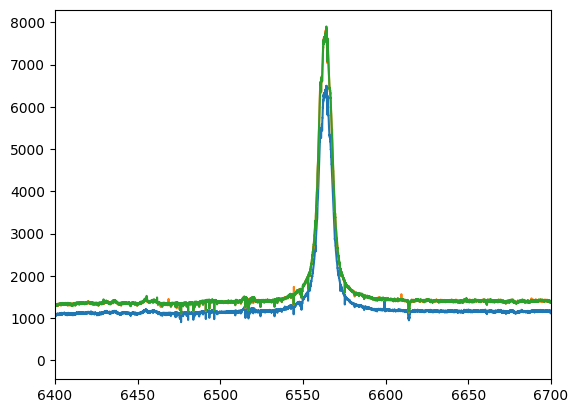

In [5]:
files1031 = [
    '091031/full/MWC_257432.txt',
    '091031/full/MWC_257433.txt',
    '091031/full/MWC_257434.txt',
]

spectra = [np.loadtxt(filename) for filename in files1031]

for spectrum in spectra: 
    plt.plot(spectrum[:, 0], spectrum[:, 1])
    plt.xlim(6400, 6700)

In [9]:
files1031

['091031/full/MWC_257432.txt',
 '091031/full/MWC_257433.txt',
 '091031/full/MWC_257434.txt']

In [10]:
spectrum = np.loadtxt(files1031[0])

In [19]:
spectrum[:,0]

array([3765.38127, 3765.40085, 3765.42043, ..., 9006.6055 , 9006.65234,
       9006.69918], shape=(167700,))

In [20]:
fluxes = []
for file in files1031: 
    spectrum = np.loadtxt(file)
    spectrum_flux = spectrum[:,1]
    fluxes.append(spectrum_flux)

freqs = spectrum[:,0]

In [ ]:
fluxes = []
for file in files1031: 
    spectrum = np.loadtxt(file)
    spectrum_flux = spectrum[:,1]
    fluxes.append(spectrum_flux)

freqs = spectrum[:,0]
median_fluxes = np.median(fluxes, axis=0)
median_fluxes_txt = np.savetxt(median_fluxes, 'median_flux.txt')

plt.plot(freqs, median_fluxes)

In [21]:
fluxes

[array([  0.65,   3.87, -27.61, ..., 544.9 , 554.44, 552.81],
       shape=(167700,)),
 array([-10.65, -21.19,  -0.89, ..., 674.27, 670.31, 678.28],
       shape=(167700,)),
 array([-35.32, -52.64, -22.17, ..., 668.71, 684.46, 682.01],
       shape=(167700,))]

In [29]:
fluxes[1][0]

np.float64(-10.65)

In [31]:
median_test = np.array([fluxes[0][0], fluxes[1][0], fluxes[2][0]])
median_test

array([  0.65, -10.65, -35.32])

In [35]:
median_testing = np.median(median_test)
median_testing

np.float64(-10.65)

In [36]:
median_fluxes = np.median(fluxes, axis=0)
median_fluxes[0]

np.float64(-10.65)

In [37]:
median_fluxes

array([-10.65, -21.19, -22.17, ..., 668.71, 670.31, 678.28],
      shape=(167700,))

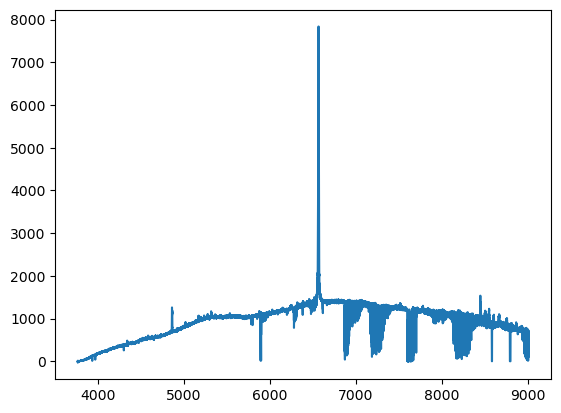

In [38]:
plt.plot(freqs, median_fluxes)

In [23]:
median_fluxes = np.median(fluxes, axis=0)

In [24]:
median_fluxes

array([-10.65, -21.19, -22.17, ..., 668.71, 670.31, 678.28],
      shape=(167700,))

In [8]:
files1031_normed_indiv = [
    '/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice/091031/full/MWC_257432.txt',
    '/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice/091031/full/MWC_257433.txt',
    '/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice/091031/full/MWC_257434.txt',
]



In [ ]:
spectra = [np.loadtxt(filename) for filename in files]

In [ ]:
/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice/091031/full/MWC_257432.txt

In [7]:
files = files1031_normed_indiv

spectra = [np.loadtxt(filename) for filename in files]

# define wavelength grid by the first spectrum as reference 
wave_ref = spectra[0][:, 0]

aligned_fluxes = []

for spectrum in spectra:
    wave = spectrum[:, 0]
    flux = spectrum[:, 1]

    # just make sure no NaNs
    valid = np.isfinite(wave) & np.isfinite(flux)
    wave = wave[valid]
    flux = flux[valid]

    # Interpolate onto reference wavelength grid
    aligned_flux = np.interp(
        wave_ref,
        wave,
        flux,
        left=np.nan,
        right=np.nan
    )

    aligned_fluxes.append(aligned_flux)

aligned_fluxes = np.array(aligned_fluxes)

common = np.all(np.isfinite(aligned_fluxes), axis=0)

wave_combined = wave_ref[common]
flux_combined = np.median(aligned_fluxes[:, common], axis=0)
flux_averaged = np.mean(aligned_fluxes[:, common], axis=0)

median_output_file = "091031/full/median_combined_1.txt"

np.savetxt(
    median_output_file,
    np.column_stack((wave_combined, flux_combined)),
    fmt="%.8f %.10e"
)
mean_output_file = "091031/full/mean_combined_1.txt"

np.savetxt(
    mean_output_file,
    np.column_stack((wave_combined, flux_averaged)),
    fmt="%.8f %.10e"
)



# --------------------------------------------------
# Inspect H-alpha
# --------------------------------------------------

plt.figure(figsize=(12, 5))

for i, flux in enumerate(aligned_fluxes):
    plt.plot(
        wave_ref,
        flux,
        alpha=0.8,
        linewidth=0.7,
        label=f"Spectrum {i + 1}"
    )

# plt.plot(
#     wave_combined,
#     flux_combined,
#     color="black",
#     linewidth=1.2,
#     label="Median combined"
# )

plt.xlim(6500, 6620)
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel("Flux")
plt.legend()
plt.show()

FileNotFoundError: EW_over_years/EW_norm_practice/091031/fits/full/MWC_257432_norm.txt not found.

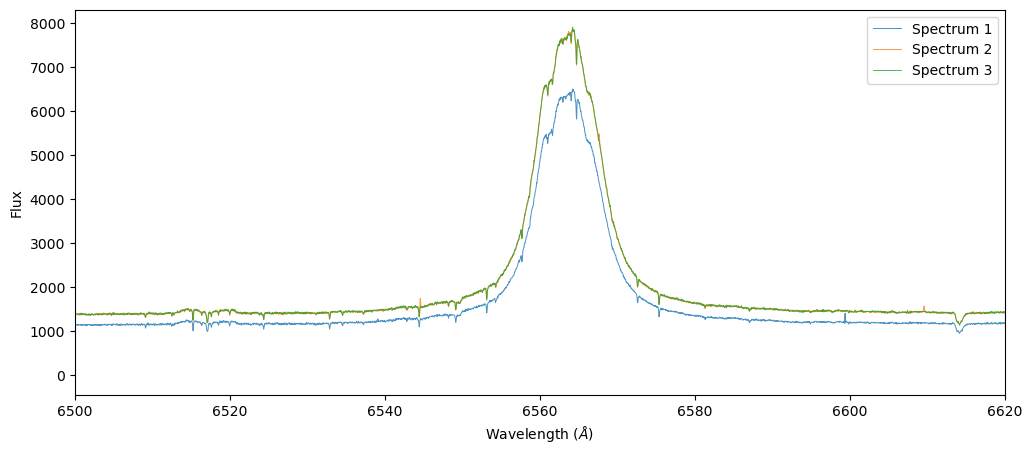

In [ ]:
files = files1031

spectra = [np.loadtxt(filename) for filename in files]

# First spectrum defines the common wavelength grid
wave_ref = spectra[0][:, 0]

#interpolating

aligned_fluxes = []

for spectrum in spectra:
    wave = spectrum[:, 0]
    flux = spectrum[:, 1]

    # removing bad values i
    valid = np.isfinite(wave) & np.isfinite(flux)
    wave = wave[valid]
    flux = flux[valid]

    # interpolating onto reference grid
    aligned_flux = np.interp(
        wave_ref,
        wave,
        flux,
        left=np.nan,
        right=np.nan
    )

    aligned_fluxes.append(aligned_flux)

aligned_fluxes = np.array(aligned_fluxes)

#keep same grid
common = np.all(np.isfinite(aligned_fluxes), axis=0)

wave_combined = wave_ref[common]
flux_combined = np.median(aligned_fluxes[:, common], axis=0)
flux_averaged = np.mean(aligned_fluxes[:, common], axis=0)

median_output_file = "091031/full/median_combined_1.txt"

np.savetxt(
    median_output_file,
    np.column_stack((wave_combined, flux_combined)),
    fmt="%.8f %.10e"
)
mean_output_file = "091031/full/mean_combined_1.txt"

np.savetxt(
    mean_output_file,
    np.column_stack((wave_combined, flux_averaged)),
    fmt="%.8f %.10e"
)

#lookin at H-alpha

plt.figure(figsize=(12, 5))

for i, flux in enumerate(aligned_fluxes):
    plt.plot(
        wave_ref,
        flux,
        alpha=0.8,
        linewidth=0.7,
        label=f"Spectrum {i + 1}"
    )

# plt.plot(
#     wave_combined,
#     flux_combined,
#     color="black",
#     linewidth=1.2,
#     label="Median combined"
# )

plt.xlim(6500, 6620)
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel("Flux")
plt.legend()
plt.show()

Okay so WHY is the first spectra so much lower?? -- realized later this is just a response function thing having to do with the telescope systematics

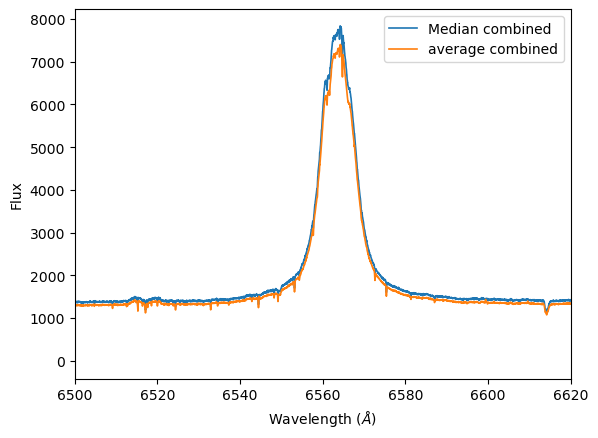

In [9]:
plt.plot(
    wave_combined,
    flux_combined,
    # color="black",
    linewidth=1.2,
    label="Median combined"
)

plt.plot(
    wave_combined,
    flux_averaged,
    # color="black",
    linewidth=1.2,
    label="average combined"
)

plt.xlim(6500, 6620)
plt.xlabel(r"Wavelength ($\AA$)")
plt.ylabel("Flux")
plt.legend()
plt.show()

In [10]:

import numpy as np

files = [
    "091031/fits/full/normalised/MWC_257432_norm.txt",
    "091031/fits/full/normalised/MWC_257433_norm.txt",
    "091031/fits/full/normalised/MWC_257433_norm.txt",
]

ews = []

for filename in files:
    data = np.loadtxt(filename)

    wave = data[:, 0]
    flux = data[:, 1]

    mask = (wave >= 6530) & (wave <= 6587)

    ew = np.trapezoid(1.0 - flux[mask], wave[mask])

    ews.append(ew)
    print(f"{filename}: EW = {ew:.4f} Å")

ews = np.array(ews)

print(f"\nMean EW = {np.mean(ews):.4f} Å")
print(f"EW scatter = {np.std(ews, ddof=1):.4f} Å")
print(f"Standard error of mean = {np.std(ews, ddof=1) / np.sqrt(3):.4f} Å")

091031/fits/full/normalised/MWC_257432_norm.txt: EW = -49.8160 Å
091031/fits/full/normalised/MWC_257433_norm.txt: EW = -49.5034 Å
091031/fits/full/normalised/MWC_257433_norm.txt: EW = -49.5034 Å

Mean EW = -49.6076 Å
EW scatter = 0.1805 Å
Standard error of mean = 0.1042 Å


Okay now running the code on the meadian spectra. 

In [11]:
pwd

'/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice'

Text(0.5, 1.0, 'Normalized Median Combined Spectrum of HD 295440, 2009-10-31')

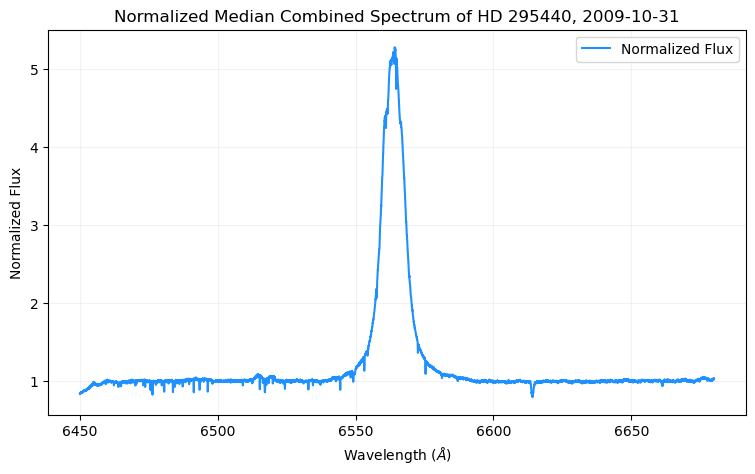

In [12]:
med_normed = np.loadtxt('091031/full/median/normalised/median_combined_1_norm.txt')
wave = med_normed[:, 0]
flux = med_normed[:, 1]
plt.figure(figsize=(9,5))
plt.plot(wave, flux, color = 'dodgerblue', label='Normalized Flux')
plt.xlabel('Wavelength ($\AA$)')
plt.ylabel('Normalized Flux')
plt.legend()
plt.grid(True, alpha=0.1, color='gray')
plt.title('Normalized Median Combined Spectrum of HD 295440, 2009-10-31')

In [13]:
pwd

'/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice'

EW = -45.0069 Angstrom
Continuum scatter = 0.034511
Statistical EW uncertainty = 0.0485 Angstrom
EW (statistical only) = -45.0069 +/- 0.0485 Angstrom


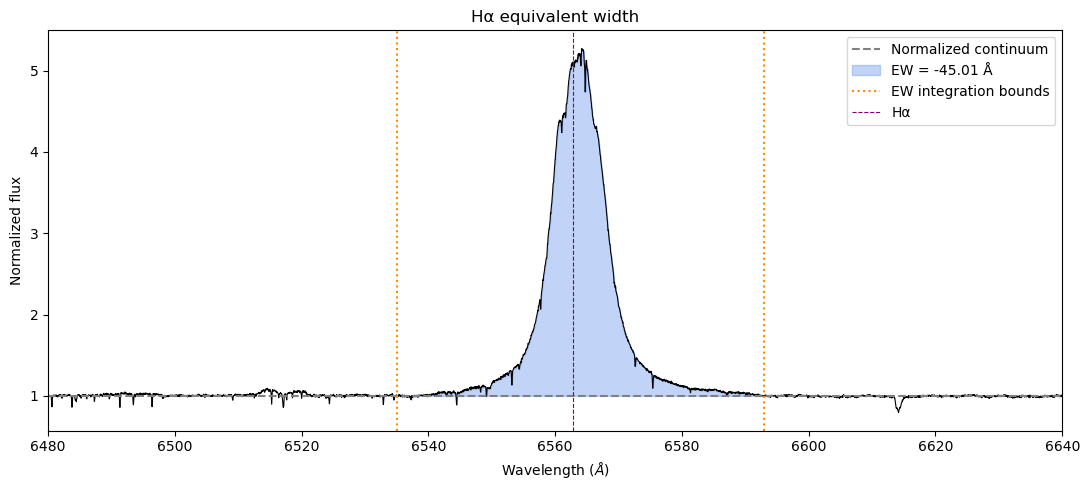

In [14]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# USER SETTINGS
# --------------------------------------------------

FILE = "/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice/091031/full/median/normalised/median_combined_1_norm.txt"

# Candidate H-alpha integration limits (Angstrom)
LINE_LEFT = 6535.0
LINE_RIGHT = 6593.0

# EXAMPLE continuum windows.
# Replace these after inspecting your normalized spectrum.
CONTINUUM_WINDOWS = [
    (6500.0, 6520.0),
    (6600.0, 6620.0),
]

# --------------------------------------------------
# LOAD NORMALIZED SPECTRUM
# --------------------------------------------------

data = np.loadtxt(FILE)

wave = data[:, 0]
flux_norm = data[:, 1]

valid = np.isfinite(wave) & np.isfinite(flux_norm)
wave = wave[valid]
flux_norm = flux_norm[valid]

order = np.argsort(wave)
wave = wave[order]
flux_norm = flux_norm[order]

# --------------------------------------------------
# SELECT H-ALPHA
# --------------------------------------------------

line_mask = (
    (wave >= LINE_LEFT) &
    (wave <= LINE_RIGHT)
)

line_wave = wave[line_mask]
line_flux = flux_norm[line_mask]

if len(line_wave) < 2:
    raise ValueError("Not enough data points inside H-alpha limits.")

# --------------------------------------------------
# EQUIVALENT WIDTH
# --------------------------------------------------

EW = np.trapezoid(
    1.0 - line_flux,
    line_wave
)

# --------------------------------------------------
# ESTIMATE CONTINUUM NOISE
# --------------------------------------------------

continuum_mask = np.zeros(len(wave), dtype=bool)

for left, right in CONTINUUM_WINDOWS:
    continuum_mask |= (wave >= left) & (wave <= right)

continuum_flux = flux_norm[continuum_mask]

if len(continuum_flux) < 2:
    raise ValueError("Not enough continuum pixels.")

# Scatter around the locally normalized continuum.
# This is an empirical noise estimate, not a continuum-fit error.
sigma_flux = np.std(continuum_flux, ddof=1)

# --------------------------------------------------
# PROPAGATE PIXEL NOISE INTO EW
# --------------------------------------------------

# Trapezoidal integration weights for potentially
# nonuniform wavelength sampling.
weights = np.empty(len(line_wave))

weights[0] = (line_wave[1] - line_wave[0]) / 2
weights[-1] = (line_wave[-1] - line_wave[-2]) / 2

weights[1:-1] = (
    line_wave[2:] - line_wave[:-2]
) / 2

# Assumes independent pixels and constant flux noise.
sigma_EW_stat = sigma_flux * np.sqrt(
    np.sum(weights**2)
)

print(f"EW = {EW:.4f} Angstrom")
print(f"Continuum scatter = {sigma_flux:.6f}")
print(f"Statistical EW uncertainty = {sigma_EW_stat:.4f} Angstrom")
print(
    f"EW (statistical only) = "
    f"{EW:.4f} +/- {sigma_EW_stat:.4f} Angstrom"
)

# --------------------------------------------------
# VISUALIZE EW
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(wave, flux_norm, color="black", lw=0.8)

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    label="Normalized continuum"
)

ax.fill_between(
    line_wave,
    1.0,
    line_flux,
    color="cornflowerblue",
    alpha=0.4,
    label=f"EW = {EW:.2f} Å"
)

ax.axvline(LINE_LEFT, color="darkorange", linestyle=":")
ax.axvline(LINE_RIGHT, color="darkorange", linestyle=":", label = 'EW integration bounds')
plt.axvline(6562.8, ls="--", label="Hα", lw = 0.8, color = 'purple')

ax.set_xlim(6480, 6640)
ax.set_xlabel(r"Wavelength ($\AA$)")
ax.set_ylabel("Normalized flux")
ax.set_title("Hα equivalent width")
ax.legend()

plt.tight_layout()
plt.show()

In [15]:
med_normed

array([[6.45000312e+03, 8.37641874e-01],
       [6.45003666e+03, 8.35851911e-01],
       [6.45007021e+03, 8.32941257e-01],
       ...,
       [6.67992004e+03, 1.02968173e+00],
       [6.67995478e+03, 1.04050089e+00],
       [6.67998952e+03, 1.03858679e+00]], shape=(6738, 2))

In [16]:
SNR_individual = 70.0  # Replace with your actual per-exposure S/N

SNR_continuum = 1.49 * SNR_individual

In [17]:
SNR_total = 107*np.sqrt(3)

def instrumental_uncertainty(SNR_total, LINE_LEFT, LINE_RIGHT): 
    # Calculate the width of the integration region in Angstroms
    delta_lambda = LINE_RIGHT - LINE_LEFT

    # Calculate the instrumental uncertainty in EW
    sigma_EW_instr = delta_lambda / SNR_total

    return sigma_EW_instr

EW                  = -45.0119 Å
Integration width   = 55.9573 Å
Mean line flux      = 1.8044
Continuum S/N       = 185.0
V&E uncertainty     = 0.9622 Å

H-alpha EW = -45.012 ± 0.962 Å (statistical estimate)


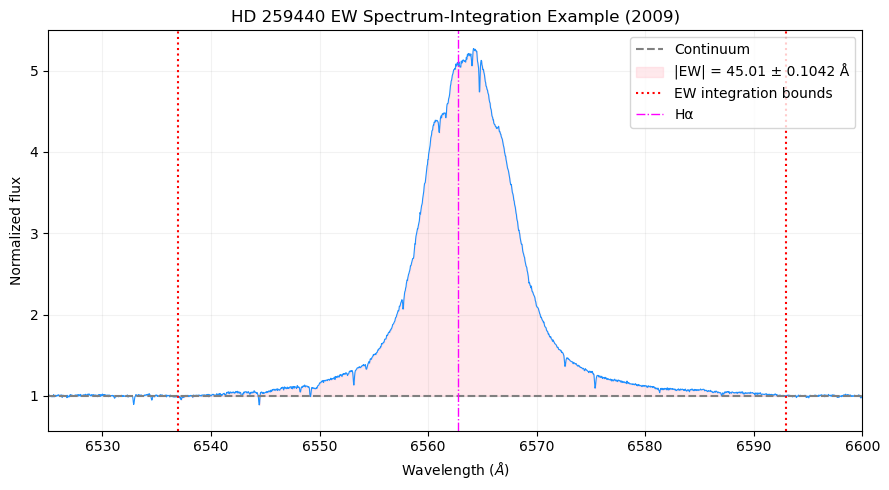

In [18]:
FILE = FILE

LINE_LEFT = 6537.0
LINE_RIGHT = 6593.0

# Estimated continuum S/N per pixel of median spectrum
SNR_CONT = 185.0

# --------------------------------------------------
# LOAD NORMALIZED SPECTRUM
# --------------------------------------------------

data = np.loadtxt(FILE)

wave = data[:, 0]
flux_norm = data[:, 1]

valid = np.isfinite(wave) & np.isfinite(flux_norm)
wave = wave[valid]
flux_norm = flux_norm[valid]

order = np.argsort(wave)
wave = wave[order]
flux_norm = flux_norm[order]

# --------------------------------------------------
# SELECT H-ALPHA REGION
# --------------------------------------------------

mask = (wave >= LINE_LEFT) & (wave <= LINE_RIGHT)

line_wave = wave[mask]
line_flux = flux_norm[mask]

if len(line_wave) < 2:
    raise ValueError("Not enough wavelength points in H-alpha window.")

# --------------------------------------------------
# EQUIVALENT WIDTH
# --------------------------------------------------

EW = np.trapezoid(
    1.0 - line_flux,
    line_wave
)

# Use the actual sampled wavelength span consistently
delta_lambda = line_wave[-1] - line_wave[0]

# Wavelength-averaged normalized flux across H-alpha
mean_line_flux = (
    np.trapezoid(line_flux, line_wave) / delta_lambda
)

# --------------------------------------------------
# VOLLMANN-EVERSBERG UNCERTAINTY
# --------------------------------------------------

mean_continuum_flux = 1.0

sigma_EW = (
    np.sqrt(2.0)
    * (delta_lambda - EW)
    / SNR_CONT
    * np.sqrt(1.0 + mean_continuum_flux / mean_line_flux)
)

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print(f"EW                  = {EW:.4f} Å")
print(f"Integration width   = {delta_lambda:.4f} Å")
print(f"Mean line flux      = {mean_line_flux:.4f}")
print(f"Continuum S/N       = {SNR_CONT:.1f}")
print(f"V&E uncertainty     = {sigma_EW:.4f} Å")

print(
    f"\nH-alpha EW = {EW:.3f} ± {sigma_EW:.3f} Å"
    " (statistical estimate)"
)

# --------------------------------------------------
# VISUALIZATION
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(wave, flux_norm, color="dodgerblue", lw=0.8)

ax.axhline(1.0, color="gray", linestyle="--",
           label="Continuum")

ax.fill_between(
    line_wave,
    1.0,
    line_flux,
    color='pink',
    alpha=0.35,
    label=f"|EW| = {np.abs(EW):.2f} ± 0.1042 Å"
)

ax.axvline(LINE_LEFT, color="red", linestyle=":", lw=1.5)
ax.axvline(LINE_RIGHT, color="red", linestyle=":",lw = 1.5, label = 'EW integration bounds')
plt.axvline(6562.8, ls="dashdot", label="Hα", lw = 1, color = 'fuchsia')

ax.set_xlim(6500, 6620)
ax.set_xlabel(r"Wavelength ($\AA$)")
ax.set_ylabel("Normalized flux")
ax.legend()
ax.grid(True, alpha=0.1, color='gray')

plt.title('HD 259440 EW Spectrum-Integration Example (2009)')
plt.tight_layout()
plt.xlim(6525, 6600)
plt.show()

In [19]:
test = instrumental_uncertainty(SNR_total, LINE_LEFT, LINE_RIGHT)

In [23]:
sigma_EW 

np.float64(0.9622458322073403)

In [20]:
test

np.float64(0.30216462686559853)

In [26]:
combined_uncertainty = np.sqrt(test**2 + 0.1042**2)

In [27]:
combined_uncertainty

np.float64(0.319626503483091)

EW = -49.2200 Angstrom
Continuum scatter = 0.032500
Statistical EW uncertainty = 0.0457 Angstrom
EW (statistical only) = -49.2200 +/- 0.0457 Angstrom


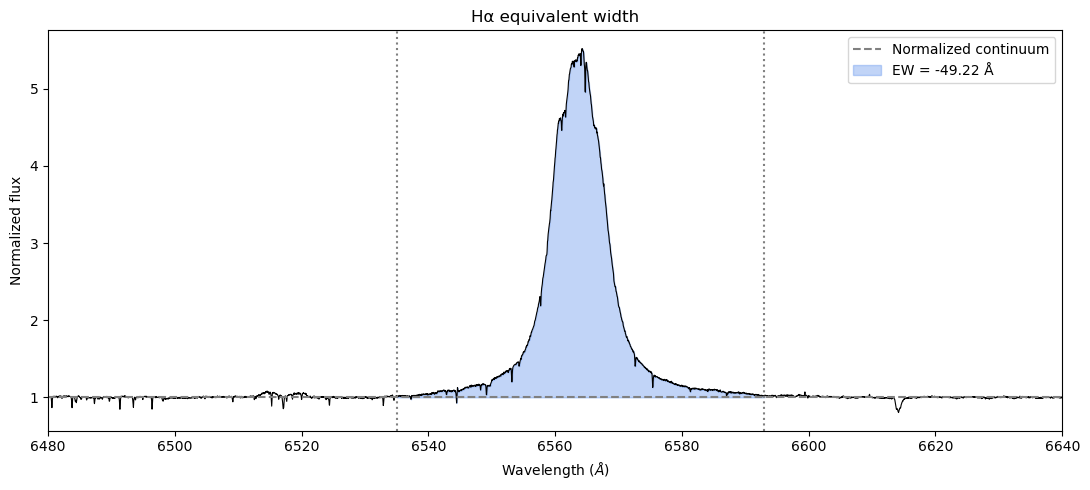

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

FILE = "/Users/leayamashiro/AnA_MSc/Observations/calculations/EW_over_years/EW_norm_practice/091031/full/mean/normalised/mean_combined_1_norm.txt"

# Candidate H-alpha integration limits (Angstrom)
LINE_LEFT = 6535.0
LINE_RIGHT = 6593.0

# EXAMPLE continuum windows.
# Replace these after inspecting your normalized spectrum.
CONTINUUM_WINDOWS = [
    (6500.0, 6520.0),
    (6600.0, 6620.0),
]

#load spectra

data = np.loadtxt(FILE)

wave = data[:, 0]
flux_norm = data[:, 1]

valid = np.isfinite(wave) & np.isfinite(flux_norm)
wave = wave[valid]
flux_norm = flux_norm[valid]

order = np.argsort(wave)
wave = wave[order]
flux_norm = flux_norm[order]

#get h-alpha
line_mask = (
    (wave >= LINE_LEFT) &
    (wave <= LINE_RIGHT)
)

line_wave = wave[line_mask]
line_flux = flux_norm[line_mask]

if len(line_wave) < 2:
    raise ValueError("Not enough data points inside H-alpha limits.")

#EW
EW = np.trapezoid(
    1.0 - line_flux,
    line_wave
)

#trying to get continuum noise
continuum_mask = np.zeros(len(wave), dtype=bool)

for left, right in CONTINUUM_WINDOWS:
    continuum_mask |= (wave >= left) & (wave <= right)

continuum_flux = flux_norm[continuum_mask]

if len(continuum_flux) < 2:
    raise ValueError("Not enough continuum pixels.")

# sigma?? 
sigma_flux = np.std(continuum_flux, ddof=1)

# getting pixel noise
weights = np.empty(len(line_wave))

weights[0] = (line_wave[1] - line_wave[0]) / 2
weights[-1] = (line_wave[-1] - line_wave[-2]) / 2

weights[1:-1] = (
    line_wave[2:] - line_wave[:-2]
) / 2

# Assumes independent pixels and constant flux noise.
sigma_EW_stat = sigma_flux * np.sqrt(
    np.sum(weights**2)
)

print(f"EW = {EW:.4f} Angstrom")
print(f"Continuum scatter = {sigma_flux:.6f}")
print(f"Statistical EW uncertainty = {sigma_EW_stat:.4f} Angstrom")
print(
    f"EW (statistical only) = "
    f"{EW:.4f} +/- {sigma_EW_stat:.4f} Angstrom"
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(wave, flux_norm, color="black", lw=0.8)

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    label="Normalized continuum"
)

ax.fill_between(
    line_wave,
    1.0,
    line_flux,
    color="cornflowerblue",
    alpha=0.4,
    label=f"EW = {EW:.2f} Å"
)

ax.axvline(LINE_LEFT, color="gray", linestyle=":")
ax.axvline(LINE_RIGHT, color="gray", linestyle=":")

ax.set_xlim(6480, 6640)
ax.set_xlabel(r"Wavelength ($\AA$)")
ax.set_ylabel("Normalized flux")
ax.set_title("Hα equivalent width")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
FILE = FILE

LINE_LEFT = 6535.0
LINE_RIGHT = 6595.0

# Estimated continuum S/N per pixel of median spectrum
SNR_CONT = 185.0

# load normed spectra

data = np.loadtxt(FILE)

wave = data[:, 0]
flux_norm = data[:, 1]

valid = np.isfinite(wave) & np.isfinite(flux_norm)
wave = wave[valid]
flux_norm = flux_norm[valid]

order = np.argsort(wave)
wave = wave[order]
flux_norm = flux_norm[order]

# get h-alpha only
mask = (wave >= LINE_LEFT) & (wave <= LINE_RIGHT)

line_wave = wave[mask]
line_flux = flux_norm[mask]

if len(line_wave) < 2:
    raise ValueError("Not enough wavelength points in H-alpha window.")

# EW

EW = np.trapezoid(
    1.0 - line_flux,
    line_wave
)

# Use the actual sampled wavelength span consistently
delta_lambda = line_wave[-1] - line_wave[0]

# Wavelength-averaged normalized flux across H-alpha
mean_line_flux = (
    np.trapezoid(line_flux, line_wave) / delta_lambda
)

# --------------------------------------------------
# VOLLMANN-EVERSBERG UNCERTAINTY
# --------------------------------------------------

mean_continuum_flux = 1.0

sigma_EW = (
    np.sqrt(2.0)
    * (delta_lambda - EW)
    / SNR_CONT
    * np.sqrt(1.0 + mean_continuum_flux / mean_line_flux)
)

print(f"EW                  = {EW:.4f} Å")
print(f"Integration width   = {delta_lambda:.4f} Å")
print(f"Mean line flux      = {mean_line_flux:.4f}")
print(f"Continuum S/N       = {SNR_CONT:.1f}")
print(f"V&E uncertainty     = {sigma_EW:.4f} Å")

print(
    f"\nH-alpha EW = {EW:.3f} ± {sigma_EW:.3f} Å"
    " (statistical estimate)"
)


fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(wave, flux_norm, color="black", lw=0.8)

ax.axhline(1.0, color="gray", linestyle="--",
           label="Continuum")

ax.fill_between(
    line_wave,
    1.0,
    line_flux,
    alpha=0.35,
    label=f"EW = {EW:.2f} ± {sigma_EW:.2f} Å"
)

ax.axvline(LINE_LEFT, color="gray", linestyle=":")
ax.axvline(LINE_RIGHT, color="gray", linestyle=":")

ax.set_xlim(6500, 6620)
ax.set_xlabel(r"Wavelength ($\AA$)")
ax.set_ylabel("Normalized flux")
ax.legend()

plt.tight_layout()
plt.show()

NameError: name 'FILE' is not defined